# Iris Dataset using DataFrame

**Name:** Naman Sharma  
**Roll No:** 1024160039

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [2]:
iris_data = load_iris(as_frame=True)
iris_df = iris_data.frame

species_names = dict(enumerate(iris_data.target_names))
iris_df["species"] = iris_df["target"].map(species_names)
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
print("Shape:", iris_df.shape)
print("Columns:", list(iris_df.columns))
print("\nMissing values:")
print(iris_df.isnull().sum())

Shape: (150, 6)
Columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [4]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [5]:
iris_df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [6]:
species_summary = iris_df.groupby("species").agg(
    flower_count=("species", "count"),
    average_sepal_length=("sepal length (cm)", "mean"),
    average_petal_length=("petal length (cm)", "mean")
)
species_summary.round(2)

,flower_count,average_sepal_length,average_petal_length
species,,,
setosa,50,5.01,1.46
versicolor,50,5.94,4.26
virginica,50,6.59,5.55


In [7]:
long_petals = iris_df[iris_df["petal length (cm)"] > 4.5]
long_petals = long_petals.sort_values("petal length (cm)", ascending=False)
long_petals[["petal length (cm)", "petal width (cm)", "species"]].head(10)

,petal length (cm),petal width (cm),species
118,6.9,2.3,virginica
122,6.7,2.0,virginica
117,6.7,2.2,virginica
105,6.6,2.1,virginica
131,6.4,2.0,virginica
107,6.3,1.8,virginica
109,6.1,2.5,virginica
130,6.1,1.9,virginica
135,6.1,2.3,virginica
125,6.0,1.8,virginica


In [8]:
iris_df["sepal area"] = iris_df["sepal length (cm)"] * iris_df["sepal width (cm)"]
iris_df["petal area"] = iris_df["petal length (cm)"] * iris_df["petal width (cm)"]
iris_df[["sepal area", "petal area", "species"]].head()

,sepal area,petal area,species
0,17.85,0.28,setosa
1,14.70,0.28,setosa
2,15.04,0.26,setosa
3,14.26,0.30,setosa
4,18.00,0.28,setosa


In [9]:
measurements = iris_df[iris_data.feature_names].to_numpy()

numpy_summary = pd.DataFrame({
    "feature": iris_data.feature_names,
    "mean": np.mean(measurements, axis=0).round(2),
    "standard deviation": np.std(measurements, axis=0).round(2),
    "minimum": np.min(measurements, axis=0),
    "maximum": np.max(measurements, axis=0)
})

numpy_summary

,feature,mean,standard deviation,minimum,maximum
0,sepal length (cm),5.84,0.83,4.3,7.9
1,sepal width (cm),3.06,0.43,2.0,4.4
2,petal length (cm),3.76,1.76,1.0,6.9
3,petal width (cm),1.20,0.76,0.1,2.5


In [10]:
conditions = [
    iris_df["petal length (cm)"] < 2.0,
    iris_df["petal length (cm)"] < 5.0
]

iris_df["petal size"] = np.select(
    conditions,
    ["small", "medium"],
    default="large"
)

iris_df[["petal length (cm)", "petal size", "species"]].head(10)

,petal length (cm),petal size,species
0,1.4,small,setosa
1,1.4,small,setosa
2,1.3,small,setosa
3,1.5,small,setosa
4,1.4,small,setosa
5,1.7,small,setosa
6,1.4,small,setosa
7,1.5,small,setosa
8,1.4,small,setosa
9,1.5,small,setosa


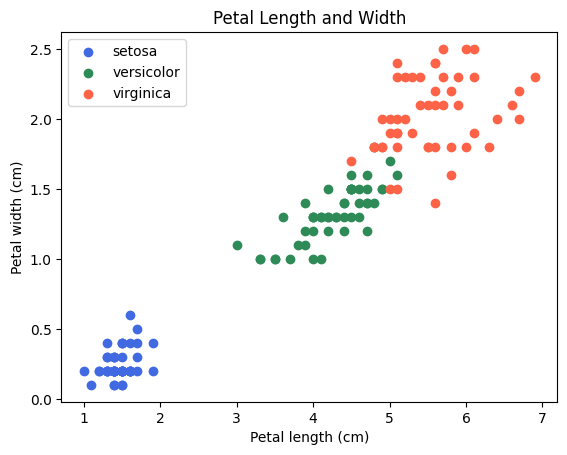

In [11]:
colors = {"setosa": "royalblue", "versicolor": "seagreen", "virginica": "tomato"}

for species, group in iris_df.groupby("species"):
    plt.scatter(
        group["petal length (cm)"],
        group["petal width (cm)"],
        label=species,
        color=colors[species]
    )

plt.title("Petal Length and Width")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend()
plt.show()

In [12]:
iris_changed = iris_df.drop(index=4)
iris_changed = iris_changed.drop(columns=iris_df.columns[3])
iris_changed.head()

,sepal length (cm),sepal width (cm),petal length (cm),target,species,sepal area,petal area,petal size
0,5.1,3.5,1.4,0,setosa,17.85,0.28,small
1,4.9,3.0,1.4,0,setosa,14.70,0.28,small
2,4.7,3.2,1.3,0,setosa,15.04,0.26,small
3,4.6,3.1,1.5,0,setosa,14.26,0.30,small
5,5.4,3.9,1.7,0,setosa,21.06,0.68,small


In [13]:
iris_changed.to_csv("Naman_iris_data.csv", index=False)
print("File saved")

File saved
